# FraudShield AI
### AI-Powered Credit Card Fraud Detection

**Hackathon:** Veritas AI International High School Hackathon 2026  
**Track:** AI + Finance  
**Project:** 4.2.2 Card Fraud Detection

## Objective
Build a machine-learning system that flags potentially fraudulent credit-card transactions and explains its results and limitations. AI/ML is the central project component.

## Public dataset
Use the public [Credit Card Fraud Detection dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) from the ULB Machine Learning Group. It contains 284,807 anonymized European card transactions over two days, including 492 fraud cases. Features V1–V28 are PCA-transformed; Time is elapsed seconds; Amount is the transaction amount; Class is the fraud label. Record the actual Kaggle download date and dataset version before submission. The Kaggle card was checked on 2026-11-14 and lists: ‘Database: Open Database, Contents: Database Contents’ (ODbL 1.0 for the database; DbCL 1.0 for the contents). Recheck the card before submission.

## Evaluation plan
1. Validate columns, row count, labels, missing values, duplicates, time range, and class balance.
2. Remove exact duplicate rows after confirming no conflicting labels. Create chronological 70% / 15% / 15% train, validation, and test splits, grouped by timestamp. Confirm fraud counts and non-overlapping time ranges.
3. Compare a majority-class DummyClassifier baseline with Logistic Regression and Random Forest. Fit preprocessing on training data only.
4. Select each model's decision threshold on validation data by maximizing F1. Report Precision, Recall, F1-score, PR-AUC (Average Precision), ROC-AUC, Accuracy, classification report, and confusion matrix on the held-out test period.

## Hackathon guardrails and current status
- Use public or synthetic data only; do not add private card data or credentials.
- Data preparation, chronological split checks, model comparison, threshold analysis, prediction checks, and repeatability checks are complete. Logistic Regression coefficients and a Random Forest feature-importance chart are included as model explanations; both describe associations, not causes.
- Random Forest was selected using validation metrics. On the test period it achieved PR-AUC 0.7734, Precision 0.8864, Recall 0.7500, and F1-score 0.8125. It detected 39 of 52 fraud cases and produced 5 false alerts.
- The test period covers only two days and contains 52 fraud cases. Results may differ on other periods. Model scores are not calibrated fraud probabilities.
- At submission, disclose the dataset source, verified license/terms, download date, software/libraries, and AI assistance.

## Tools
Python, NumPy, Pandas, scikit-learn, Matplotlib, and Google Colab.

In [ ]:
# FraudShield AI — environment initialization (no data/model training here)
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score, precision_score, recall_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path("/content")
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = DATA_DIR / "creditcard.csv"

print("FraudShield AI environment initialized")
print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")
print(f"Dataset path: {DATA_PATH} (present: {DATA_PATH.exists()})")
print("Metrics planned: Precision, Recall, Average Precision (PR-AUC)")

FraudShield AI environment initialized
Python: 3.13.18
NumPy: 2.4.6 | Pandas: 2.2.3 | scikit-learn: 1.6.1
Dataset path: /content/data/creditcard.csv (present: False)
Metrics planned: Precision, Recall, Average Precision (PR-AUC)


In [ ]:
# Environment setup is performed in the first code cell.
# This legacy cell is intentionally a no-op.

In [13]:
# Upload and validate the public Kaggle CSV. This cell does not train a model.
from pathlib import Path
import numpy as np
import pandas as pd
from google.colab import files

DATA_DIR = Path("/content/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = DATA_DIR / "creditcard.csv"

if not DATA_PATH.exists():
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
    if len(csv_files) != 1:
        raise ValueError("Upload exactly one CSV file. If you downloaded a ZIP, extract it first.")
    source_name = csv_files[0]
    file_bytes = uploaded[source_name]
    if not file_bytes:
        raise ValueError("The uploaded CSV is empty.")
    DATA_PATH.write_bytes(file_bytes)
    del uploaded, file_bytes
    print(f"Saved {source_name} to {DATA_PATH} ({DATA_PATH.stat().st_size:,} bytes)")
else:
    print(f"Using existing dataset at {DATA_PATH} ({DATA_PATH.stat().st_size:,} bytes)")

try:
    df = pd.read_csv(DATA_PATH)
except Exception as error:
    raise ValueError(f"Could not parse the CSV file: {error}") from error

expected_columns = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount", "Class"]
if not df.columns.is_unique:
    raise ValueError("The CSV contains duplicate column names.")
if df.empty:
    raise ValueError("The CSV contains no data rows.")
missing_columns = sorted(set(expected_columns) - set(df.columns))
unexpected_columns = sorted(set(df.columns) - set(expected_columns))
if missing_columns or unexpected_columns:
    raise ValueError(
        f"Unexpected dataset schema. Missing columns: {missing_columns}; "
        f"unexpected columns: {unexpected_columns}."
    )
df = df.loc[:, expected_columns]
non_numeric_columns = [
    column for column in expected_columns
    if not pd.api.types.is_numeric_dtype(df[column])
]
if non_numeric_columns:
    raise ValueError(f"Expected numeric values in columns: {non_numeric_columns}")
missing_by_column = df.isna().sum()
if missing_by_column.any():
    raise ValueError(
        "Missing values found: "
        + str(missing_by_column[missing_by_column > 0].to_dict())
    )
if not np.isfinite(df.to_numpy(dtype=np.float64, copy=False)).all():
    raise ValueError("The dataset contains infinite or non-finite numeric values.")
if not df["Class"].isin([0, 1]).all():
    raise ValueError("The target column 'Class' must contain only 0 and 1.")
if df["Class"].nunique() != 2:
    raise ValueError("Both normal and fraud classes must be present.")
if (df["Time"] < 0).any() or (df["Amount"] < 0).any():
    raise ValueError("Time and Amount must be non-negative for this dataset.")

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Missing values: {int(df.isna().sum().sum()):,}")
print(f"Duplicate rows: {int(df.duplicated().sum()):,}")
print("Class counts:", df["Class"].value_counts().sort_index().to_dict())
print(f"Time sorted ascending: {df['Time'].is_monotonic_increasing}")
print(f"Time range: {df['Time'].min()} to {df['Time'].max()} seconds")
print("Dataset schema and value checks passed. No model trained.")

Using existing dataset at /content/data/creditcard.csv (150,828,752 bytes)
Dataset shape: 284,807 rows x 31 columns
Missing values: 0
Duplicate rows: 1,081
Class counts: {0: 284315, 1: 492}
Time sorted ascending: True
Time range: 0.0 to 172792.0 seconds
Dataset schema and value checks passed. No model trained.


In [4]:
# Audit exact duplicates without removing rows or training a model.
from pathlib import Path
import pandas as pd

DATA_PATH = Path("/content/data/creditcard.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("The dataset is not present in this runtime. Rerun the upload and validation cell first.")

df = pd.read_csv(DATA_PATH)
redundant_mask = df.duplicated(keep="first")
all_duplicate_mask = df.duplicated(keep=False)

print(f"Redundant exact duplicate rows: {int(redundant_mask.sum()):,}")
print(f"Rows in exact-duplicate groups: {int(all_duplicate_mask.sum()):,}")
print("Redundant duplicate rows by class:", df.loc[redundant_mask, "Class"].value_counts().sort_index().to_dict())

feature_columns = [column for column in df.columns if column != "Class"]
feature_hashes = pd.util.hash_pandas_object(df[feature_columns], index=False)
audit = pd.DataFrame({"feature_hash": feature_hashes, "Class": df["Class"].to_numpy()})
label_counts = audit.groupby("feature_hash", sort=False)["Class"].nunique()
conflicting_hashes = label_counts[label_counts > 1].index

print(f"Feature-identical groups with conflicting labels: {len(conflicting_hashes):,}")
print(f"Rows in conflicting-label groups: {int(audit['feature_hash'].isin(conflicting_hashes).sum()):,}")
print("No rows removed; no model trained.")

Redundant exact duplicate rows: 1,081
Rows in exact-duplicate groups: 1,854
Redundant duplicate rows by class: {0: 1062, 1: 19}
Feature-identical groups with conflicting labels: 0
Rows in conflicting-label groups: 0
No rows removed; no model trained.


In [5]:
import numpy as np

# Keep one copy of each exact row; preserve the original df.
df_prepared = df.drop_duplicates(keep="first").copy()
df_prepared = df_prepared.sort_values("Time", kind="mergesort").reset_index(drop=True)

if df_prepared.duplicated().any():
    raise ValueError("Exact duplicates remain after deduplication.")

n_rows = len(df_prepared)
unique_times, rows_per_time = np.unique(
    df_prepared["Time"].to_numpy(),
    return_counts=True
)
cumulative_rows = np.cumsum(rows_per_time)

train_boundary_index = int(
    np.searchsorted(cumulative_rows, 0.70 * n_rows, side="left")
)
validation_boundary_index = int(
    np.searchsorted(cumulative_rows, 0.85 * n_rows, side="left")
)

if not 0 <= train_boundary_index < validation_boundary_index < len(unique_times):
    raise ValueError("Could not create valid chronological split boundaries.")

train_cutoff = unique_times[train_boundary_index]
validation_cutoff = unique_times[validation_boundary_index]

train_df = df_prepared[df_prepared["Time"] <= train_cutoff].copy()
val_df = df_prepared[
    (df_prepared["Time"] > train_cutoff)
    & (df_prepared["Time"] <= validation_cutoff)
].copy()
test_df = df_prepared[df_prepared["Time"] > validation_cutoff].copy()

splits = {"Train": train_df, "Validation": val_df, "Test": test_df}

if any(part.empty for part in splits.values()):
    raise ValueError("At least one chronological split is empty.")

print(f"Rows before deduplication: {len(df):,}")
print(f"Exact duplicate rows removed: {len(df) - len(df_prepared):,}")
print(f"Rows after deduplication: {len(df_prepared):,}")
print(
    "Class counts after deduplication:",
    df_prepared["Class"].value_counts().sort_index().to_dict()
)

for name, part in splits.items():
    fraud_count = int(part["Class"].sum())
    print(
        f"{name}: {len(part):,} rows "
        f"({len(part) / n_rows:.1%}), "
        f"frauds: {fraud_count:,}, "
        f"fraud rate: {part['Class'].mean():.3%}, "
        f"Time: {part['Time'].min()} to {part['Time'].max()} seconds"
    )

if not (train_df["Time"].max() < val_df["Time"].min()):
    raise ValueError("Train and validation time ranges overlap.")
if not (val_df["Time"].max() < test_df["Time"].min()):
    raise ValueError("Validation and test time ranges overlap.")
if any(int(part["Class"].sum()) == 0 for part in splits.values()):
    raise ValueError("At least one split contains no fraud cases.")

print("Chronological split checks passed. No model trained.")

Rows before deduplication: 284,807
Exact duplicate rows removed: 1,081
Rows after deduplication: 283,726
Class counts after deduplication: {0: 283253, 1: 473}
Train: 198,609 rows (70.0%), frauds: 366, fraud rate: 0.184%, Time: 0.0 to 132906.0 seconds
Validation: 42,560 rows (15.0%), frauds: 55, fraud rate: 0.129%, Time: 132907.0 to 151320.0 seconds
Test: 42,557 rows (15.0%), frauds: 52, fraud rate: 0.122%, Time: 151321.0 to 172792.0 seconds
Chronological split checks passed. No model trained.


In [6]:
import numpy as np

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

feature_columns = [column for column in train_df.columns if column != "Class"]

X_train = train_df[feature_columns]
y_train = train_df["Class"]
X_val = val_df[feature_columns]
y_val = val_df["Class"]
X_test = test_df[feature_columns]
y_test = test_df["Class"]

# Majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
baseline_positive_index = list(baseline.classes_).index(1)
baseline_scores = baseline.predict_proba(X_test)[:, baseline_positive_index]

# Supervised model; the scaler is fitted on training data only.
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42,
    ),
)
model.fit(X_train, y_train)

positive_index = list(model.classes_).index(1)
validation_scores = model.predict_proba(X_val)[:, positive_index]

# Select the decision threshold on validation data by maximizing F1.
curve_precision, curve_recall, thresholds = precision_recall_curve(
    y_val,
    validation_scores,
)
if len(thresholds) == 0:
    raise ValueError("Could not select a threshold from validation predictions.")

f1_scores = (
    2 * curve_precision[:-1] * curve_recall[:-1]
    / np.maximum(curve_precision[:-1] + curve_recall[:-1], 1e-12)
)
best_index = int(np.argmax(f1_scores))
selected_threshold = float(thresholds[best_index])

validation_predictions = (validation_scores >= selected_threshold).astype(int)
print("Validation threshold selection")
print(f"Selected threshold: {selected_threshold:.6f}")
print(f"Validation precision: {precision_score(y_val, validation_predictions, zero_division=0):.4f}")
print(f"Validation recall: {recall_score(y_val, validation_predictions, zero_division=0):.4f}")

# Evaluate on the held-out test period.
test_scores = model.predict_proba(X_test)[:, positive_index]
test_predictions = (test_scores >= selected_threshold).astype(int)

def report_metrics(name, y_true, predictions, scores, decision_rule):
    print(f"\n{name}")
    print(f"Decision rule: {decision_rule}")
    print(f"Precision: {precision_score(y_true, predictions, zero_division=0):.4f}")
    print(f"Recall: {recall_score(y_true, predictions, zero_division=0):.4f}")
    print(f"PR-AUC (Average Precision): {average_precision_score(y_true, scores):.4f}")

report_metrics(
    "Majority-class baseline on test",
    y_test,
    baseline_predictions,
    baseline_scores,
    "Always predict the most frequent class in the training set",
)
report_metrics(
    "Logistic regression on test",
    y_test,
    test_predictions,
    test_scores,
    f"Threshold {selected_threshold:.6f}, selected on validation by maximizing F1",
)

print("\nThe test set was not used for fitting or threshold selection.")

Validation threshold selection
Selected threshold: 0.999995
Validation precision: 0.9130
Validation recall: 0.7636

Majority-class baseline on test
Decision rule: Always predict the most frequent class in the training set
Precision: 0.0000
Recall: 0.0000
PR-AUC (Average Precision): 0.0012

Logistic regression on test
Decision rule: Threshold 0.999995, selected on validation by maximizing F1
Precision: 0.9429
Recall: 0.6346
PR-AUC (Average Precision): 0.7101

The test set was not used for fitting or threshold selection.


True negatives: 42,503
False positives: 2
False negatives: 19
True positives: 33


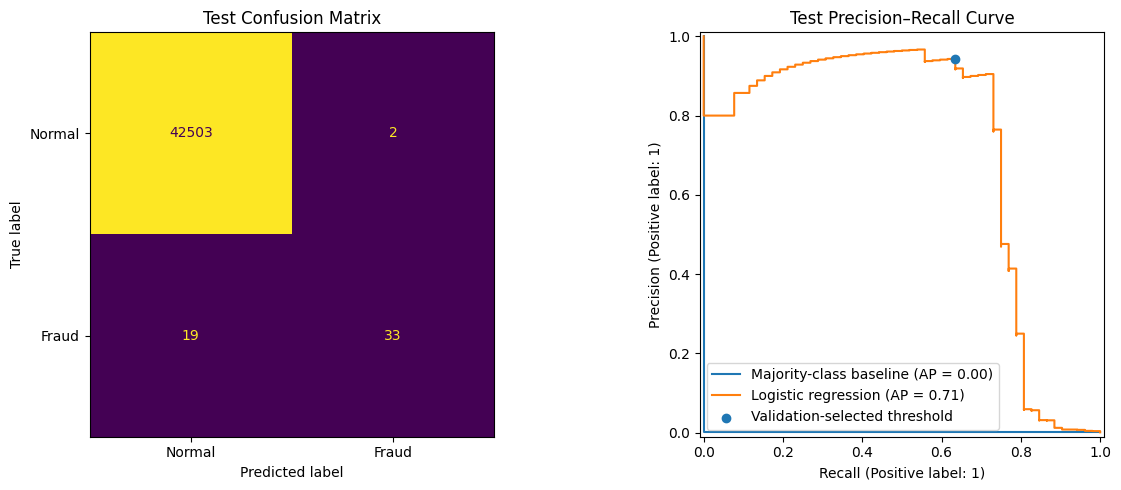

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    confusion_matrix,
)

confusion = confusion_matrix(y_test, test_predictions, labels=[0, 1])
true_normal, false_fraud_alerts, missed_frauds, detected_frauds = confusion.ravel()

print(f"True negatives: {true_normal:,}")
print(f"False positives: {false_fraud_alerts:,}")
print(f"False negatives: {missed_frauds:,}")
print(f"True positives: {detected_frauds:,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=["Normal", "Fraud"],
).plot(ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("Test Confusion Matrix")

PrecisionRecallDisplay.from_predictions(
    y_test,
    baseline_scores,
    name="Majority-class baseline",
    ax=axes[1],
)
PrecisionRecallDisplay.from_predictions(
    y_test,
    test_scores,
    name="Logistic regression",
    ax=axes[1],
)
axes[1].scatter(
    recall_score(y_test, test_predictions, zero_division=0),
    precision_score(y_test, test_predictions, zero_division=0),
    label="Validation-selected threshold",
    zorder=3,
)
axes[1].set_title("Test Precision–Recall Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

classifier = model.named_steps["logisticregression"]
scaler = model.named_steps["standardscaler"]
coefficients = classifier.coef_[0]

feature_effects = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient": coefficients,
})
top_features = feature_effects.reindex(
    feature_effects["Coefficient"].abs()
    .sort_values(ascending=False)
    .index
).head(10).sort_values("Coefficient")

colors = [
    "crimson" if value > 0 else "steelblue"
    for value in top_features["Coefficient"]
]

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Standardized logistic regression coefficient")
plt.title("Top 10 Global Feature Effects")
plt.tight_layout()
plt.show()

print("Positive coefficients push the model score toward fraud.")
print("Negative coefficients push the model score away from fraud.")
print("These effects are associations, not causal explanations.")

# Use the first validation transaction flagged by the model, without consulting labels.
validation_predictions = (validation_scores >= selected_threshold).astype(int)
flagged_validation_positions = np.flatnonzero(validation_predictions == 1)
position = int(flagged_validation_positions[0]) if flagged_validation_positions.size else 0
scaled_row = scaler.transform(X_val.iloc[[position]])[0]
contributions = pd.Series(
    scaled_row * coefficients,
    index=feature_columns,
).sort_values()

print("\nIllustrative validation transaction; selected without using labels")
print(f"Model score: {validation_scores[position]:.6f}")
print(f"Predicted label: {'Fraud' if validation_predictions[position] == 1 else 'Normal'}")
print("Largest feature contributions toward fraud:")
print(contributions.tail(5).sort_values(ascending=False).to_string())
print("Largest feature contributions away from fraud:")
print(contributions.head(5).to_string())

In [9]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Verify chronological boundaries and training-only preprocessing.
assert train_df.index.intersection(val_df.index).empty
assert train_df.index.intersection(test_df.index).empty
assert val_df.index.intersection(test_df.index).empty
assert train_df["Time"].max() < val_df["Time"].min()
assert val_df["Time"].max() < test_df["Time"].min()
assert not df_prepared.duplicated().any()
assert np.all(
    np.asarray(model.named_steps["standardscaler"].n_samples_seen_)
    == len(X_train)
)
print("Data split and preprocessing checks passed.")

def select_f1_threshold(y_true, scores):
    precisions, recalls, thresholds = precision_recall_curve(y_true, scores)
    if len(thresholds) == 0:
        raise ValueError("No validation thresholds are available.")

    f1_values = (
        2 * precisions[:-1] * recalls[:-1]
        / np.maximum(precisions[:-1] + recalls[:-1], 1e-12)
    )
    best_index = int(np.argmax(f1_values))
    return float(thresholds[best_index])

# Train Random Forest on the training split only.
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=14,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)

rf_positive_index = list(rf_model.classes_).index(1)
rf_val_scores = rf_model.predict_proba(X_val)[:, rf_positive_index]
rf_threshold = select_f1_threshold(y_val, rf_val_scores)
rf_test_scores = rf_model.predict_proba(X_test)[:, rf_positive_index]
rf_test_predictions = (rf_test_scores >= rf_threshold).astype(int)

# Reuse the existing validation-selected Logistic Regression threshold.
logistic_test_predictions = (test_scores >= selected_threshold).astype(int)
baseline_test_predictions = baseline.predict(X_test)
baseline_positive_index = list(baseline.classes_).index(1)
baseline_test_scores = baseline.predict_proba(X_test)[:, baseline_positive_index]

models_to_report = [
    (
        "Majority-class baseline",
        baseline_test_predictions,
        baseline_test_scores,
        "Always predict the most frequent training class",
    ),
    (
        "Logistic Regression",
        logistic_test_predictions,
        test_scores,
        f"Validation-selected threshold: {selected_threshold:.6f}",
    ),
    (
        "Random Forest",
        rf_test_predictions,
        rf_test_scores,
        f"Validation-selected threshold: {rf_threshold:.6f}",
    ),
]

for name, predictions, scores, decision_rule in models_to_report:
    print(f"\n{name}")
    print(f"Decision rule: {decision_rule}")
    print(f"Precision: {precision_score(y_test, predictions, zero_division=0):.4f}")
    print(f"Recall: {recall_score(y_test, predictions, zero_division=0):.4f}")
    print(f"F1-score: {f1_score(y_test, predictions, zero_division=0):.4f}")
    print(f"PR-AUC (Average Precision): {average_precision_score(y_test, scores):.4f}")
    print(f"ROC-AUC: {roc_auc_score(y_test, scores):.4f}")
    print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
    print("Classification report:")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["Normal", "Fraud"],
            digits=4,
            zero_division=0,
        )
    )
    print("Confusion matrix (rows=true, columns=predicted; order: Normal, Fraud):")
    print(confusion_matrix(y_test, predictions, labels=[0, 1]))

# Show how thresholds affect Precision and Recall on validation data only.
threshold_grid = sorted(
    set(
        [float(value) for value in np.linspace(0.0, 1.0, 11)]
        + [float(selected_threshold), float(rf_threshold)]
    )
)
threshold_rows = []

for name, scores in [
    ("Logistic Regression", validation_scores),
    ("Random Forest", rf_val_scores),
]:
    for threshold in threshold_grid:
        validation_predictions = (scores >= threshold).astype(int)
        threshold_rows.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, validation_predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, validation_predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, validation_predictions, zero_division=0
            ),
        })

threshold_table = pd.DataFrame(threshold_rows)
print("\nThreshold sensitivity on validation data")
print(threshold_table.to_string(index=False))

# Check that prediction labels and scores are valid.
prediction_checks = [
    ("Baseline", baseline_test_predictions, baseline_test_scores),
    ("Logistic Regression", logistic_test_predictions, test_scores),
    ("Random Forest", rf_test_predictions, rf_test_scores),
]
for name, predictions, scores in prediction_checks:
    assert np.isin(predictions, [0, 1]).all()
    assert np.isfinite(scores).all()
    assert ((scores >= 0) & (scores <= 1)).all()
    print(f"{name} prediction checks passed.")

# Repeat each seeded model fit on training data and compare validation scores.
for name, fitted_model, expected_scores in [
    ("Logistic Regression", model, validation_scores),
    ("Random Forest", rf_model, rf_val_scores),
]:
    repeated_model = clone(fitted_model)
    repeated_model.fit(X_train, y_train)
    positive_index = list(repeated_model.classes_).index(1)
    repeated_scores = repeated_model.predict_proba(X_val)[:, positive_index]
    assert np.allclose(
        expected_scores,
        repeated_scores,
        rtol=1e-8,
        atol=1e-10,
    )
    print(f"{name} repeatability check passed.")

print("\nTest data was not used for fitting or threshold selection.")

Data split and preprocessing checks passed.

Majority-class baseline
Decision rule: Always predict the most frequent training class
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000
PR-AUC (Average Precision): 0.0012
ROC-AUC: 0.5000
Accuracy: 0.9988
Classification report:
              precision    recall  f1-score   support

      Normal     0.9988    1.0000    0.9994     42505
       Fraud     0.0000    0.0000    0.0000        52

    accuracy                         0.9988     42557
   macro avg     0.4994    0.5000    0.4997     42557
weighted avg     0.9976    0.9988    0.9982     42557

Confusion matrix (rows=true, columns=predicted; order: Normal, Fraud):
[[42505     0]
 [   52     0]]

Logistic Regression
Decision rule: Validation-selected threshold: 0.999995
Precision: 0.9429
Recall: 0.6346
F1-score: 0.7586
PR-AUC (Average Precision): 0.7101
ROC-AUC: 0.9773
Accuracy: 0.9995
Classification report:
              precision    recall  f1-score   support

      Normal     0.9996   

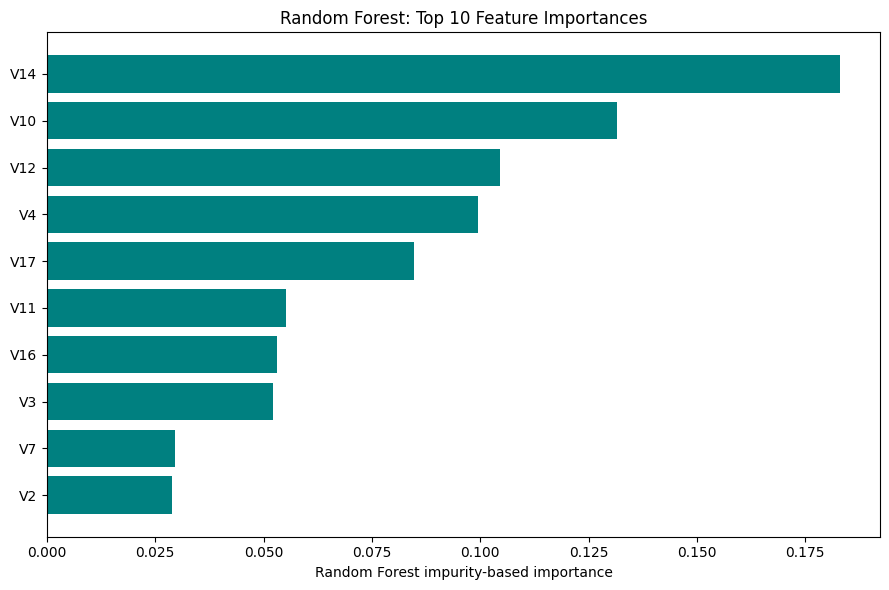

Importances describe how the forest used training-set features to reduce impurity.
They are associations, not causal explanations, and can favor features with more split opportunities.


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_columns,
    name="Impurity-based importance",
).sort_values(ascending=False)

top_rf_importance = rf_importance.head(10).sort_values()
plt.figure(figsize=(9, 6))
plt.barh(top_rf_importance.index, top_rf_importance.values, color="teal")
plt.xlabel("Random Forest impurity-based importance")
plt.title("Random Forest: Top 10 Feature Importances")
plt.tight_layout()
plt.show()

print("Importances describe how the forest used training-set features to reduce impurity.")
print("They are associations, not causal explanations, and can favor features with more split opportunities.")

Validation metrics for model selection
              Model  Threshold  Precision   Recall  F1-score   PR-AUC  ROC-AUC
Logistic Regression   0.999995   0.913043 0.763636  0.831683 0.836650 0.982428
      Random Forest   0.372909   1.000000 0.781818  0.877551 0.860219 0.982519

Final test metrics
                  Model  Precision   Recall  F1-score   PR-AUC  ROC-AUC  Accuracy
Majority-class baseline   0.000000 0.000000  0.000000 0.001222 0.500000  0.998778
    Logistic Regression   0.942857 0.634615  0.758621 0.710117 0.977335  0.999507
          Random Forest   0.886364 0.750000  0.812500 0.773384 0.925100  0.999577
Test results are for reporting; do not use them to tune thresholds.


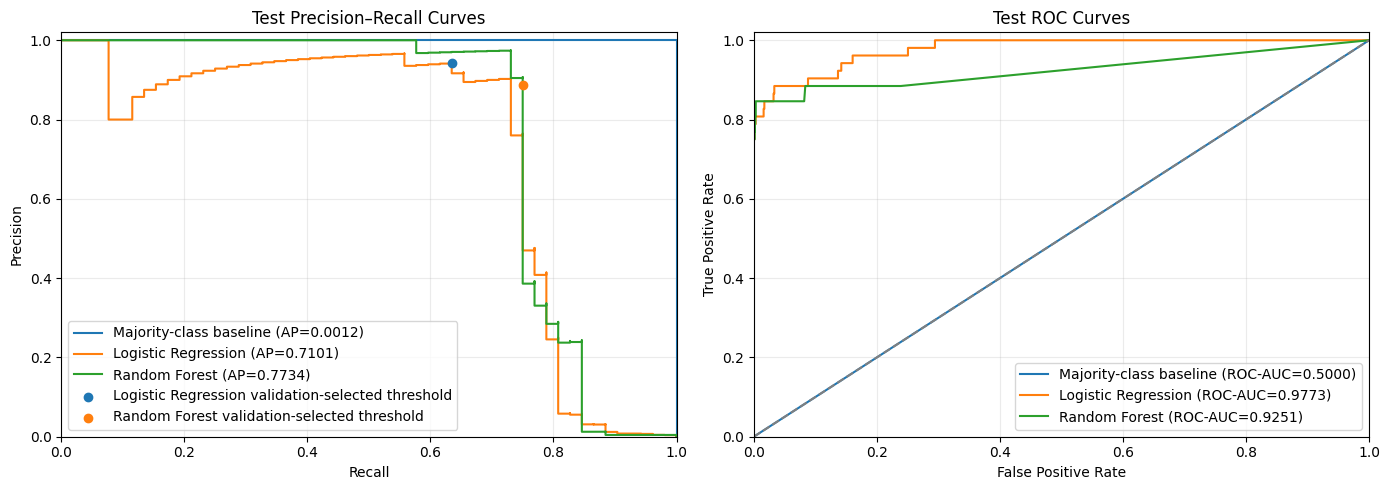

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# Use validation metrics to compare the supervised models.
validation_rows = []

for name, scores, threshold in [
    ("Logistic Regression", validation_scores, selected_threshold),
    ("Random Forest", rf_val_scores, rf_threshold),
]:
    predictions = (scores >= threshold).astype(int)
    validation_rows.append({
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_val, scores),
        "ROC-AUC": roc_auc_score(y_val, scores),
    })

print("Validation metrics for model selection")
print(pd.DataFrame(validation_rows).to_string(index=False))

# Summarize the final test results for reporting.
test_models = [
    ("Majority-class baseline", baseline_test_predictions, baseline_test_scores),
    ("Logistic Regression", logistic_test_predictions, test_scores),
    ("Random Forest", rf_test_predictions, rf_test_scores),
]

test_rows = []
for name, predictions, scores in test_models:
    test_rows.append({
        "Model": name,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_test, scores),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Accuracy": accuracy_score(y_test, predictions),
    })

print("\nFinal test metrics")
print(pd.DataFrame(test_rows).to_string(index=False))
print("Test results are for reporting; do not use them to tune thresholds.")

# Plot test curves with exact metric values in the legend.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, predictions, scores in test_models:
    precision_values, recall_values, _ = precision_recall_curve(y_test, scores)
    average_precision = average_precision_score(y_test, scores)

    axes[0].step(
        recall_values[::-1],
        precision_values[::-1],
        where="post",
        label=f"{name} (AP={average_precision:.4f})",
    )

    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, scores)
    roc_auc = roc_auc_score(y_test, scores)
    axes[1].plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{name} (ROC-AUC={roc_auc:.4f})",
    )

for name, predictions, scores in test_models[1:]:
    axes[0].scatter(
        recall_score(y_test, predictions, zero_division=0),
        precision_score(y_test, predictions, zero_division=0),
        label=f"{name} validation-selected threshold",
        zorder=3,
    )

axes[0].set_title("Test Precision–Recall Curves")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("Test ROC Curves")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.tight_layout()
plt.show()

# Final Results and Interpretation

## Chronological data splits

| Split | Transactions | Fraud cases | Fraud rate | Time range (seconds) |
|---|---:|---:|---:|---:|
| Train | 198,609 | 366 | 0.184% | 0–132,906 |
| Validation | 42,560 | 55 | 0.129% | 132,907–151,320 |
| Test | 42,557 | 52 | 0.122% | 151,321–172,792 |

The data was sorted by time, exact duplicates were removed after checking for conflicting labels, and the time ranges do not overlap. Scaling for Logistic Regression was fitted on the training split only. Each model's threshold was selected on validation data by maximizing F1. The test split was reserved for final reporting.

## Validation metrics used for model selection

| Model | Selected threshold | Precision | Recall | F1-score | PR-AUC | ROC-AUC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.999995 | 0.9130 | 0.7636 | 0.8317 | 0.8367 | 0.9824 |
| Random Forest | 0.372909 | 1.0000 | 0.7818 | 0.8776 | 0.8602 | 0.9825 |

Random Forest was selected as the primary model because it had the strongest validation F1 and PR-AUC. The majority-class model is the baseline; its near-perfect accuracy does not mean it detects fraud.

## Final held-out test metrics

| Model | Precision | Recall | F1-score | PR-AUC (Average Precision) | ROC-AUC | Accuracy | Threshold |
|---|---:|---:|---:|---:|---:|---:|---:|
| Majority-class baseline | 0.0000 | 0.0000 | 0.0000 | 0.0012 | 0.5000 | 0.9988 | Always normal |
| Logistic Regression | 0.9429 | 0.6346 | 0.7586 | 0.7101 | 0.9773 | 0.9995 | 0.999995 |
| Random Forest | 0.8864 | 0.7500 | 0.8125 | 0.7734 | 0.9251 | 0.9996 | 0.372909 |

Confusion matrices use rows = actual class and columns = predicted class, in the order Normal, Fraud:

| Model | True negatives | False alerts | Missed frauds | Detected frauds |
|---|---:|---:|---:|---:|
| Majority-class baseline | 42,505 | 0 | 52 | 0 |
| Logistic Regression | 42,503 | 2 | 19 | 33 |
| Random Forest | 42,500 | 5 | 13 | 39 |

On this test period, Random Forest detected 39 of 52 fraud cases, missed 13, and produced 5 false alerts. Logistic Regression detected 33, missed 19, and produced 2 false alerts. This shows the operational tradeoff: Random Forest catches more fraud, while Logistic Regression produces fewer false alerts and has higher test precision. The classification reports and PR/ROC curves are included in the evaluation cells above.

## Model interpretation

The Logistic Regression coefficient chart and example transaction explanation describe associations in that model; they are not causal explanations. V1–V28 are anonymized PCA components, so they cannot be translated directly into recognizable purchase reasons. The Random Forest is the selected model; its feature-importance chart should be interpreted as a ranking of model reliance, not as proof of cause.

## Limitations

The dataset covers only two days, and the test period contains 52 fraud cases, so the estimates are uncertain and may not generalize to new time periods, issuers, or live transactions. The thresholds are score cutoffs, not calibrated fraud probabilities. No external dataset or production system has been evaluated.

## Data and tools disclosure

Dataset: public Credit Card Fraud Detection dataset by the ULB Machine Learning Group, obtained from Kaggle.  
Access date: [enter the actual date the dataset was downloaded from Kaggle].  
Dataset version: [enter the version downloaded from Kaggle].  
License shown on the Kaggle card (checked 2026-11-14): Database: Open Database, Contents: Database Contents (ODbL 1.0 for the database; DbCL 1.0 for the contents).  
Tools: Python 3.13.18, NumPy 2.4.6, Pandas 2.2.3, scikit-learn 1.6.1, Matplotlib, and Google Colab.  
AI assistance: ChatGPT/Codex assisted with planning, code drafting, debugging guidance, and result interpretation. The project author reviewed the notebook and ran the cells.

In [12]:
def predict_transactions(transaction_data, threshold=rf_threshold):
    """Score transactions with the selected Random Forest model."""
    if not isinstance(transaction_data, pd.DataFrame):
        raise TypeError("transaction_data must be a pandas DataFrame.")
    if transaction_data.empty:
        raise ValueError("Provide at least one transaction to score.")
    if not transaction_data.columns.is_unique:
        raise ValueError("Input column names must be unique.")

    missing_columns = [
        column for column in feature_columns
        if column not in transaction_data.columns
    ]
    if missing_columns:
        raise ValueError(f"Missing required feature columns: {missing_columns}")

    try:
        threshold = float(threshold)
    except (TypeError, ValueError) as error:
        raise ValueError("threshold must be a number between 0 and 1.") from error
    if not np.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError("threshold must be a finite number between 0 and 1.")

    features = transaction_data.loc[:, feature_columns].copy()
    try:
        features = features.apply(pd.to_numeric, errors="raise")
    except (TypeError, ValueError) as error:
        raise ValueError("All required feature values must be numeric.") from error

    if features.isna().any().any():
        raise ValueError("Input features contain missing values.")
    if not np.isfinite(features.to_numpy(dtype=np.float64)).all():
        raise ValueError("Input features contain infinite or non-finite values.")

    fraud_scores = rf_model.predict_proba(features)[:, rf_positive_index]
    predicted_classes = (fraud_scores >= threshold).astype(int)
    return pd.DataFrame(
        {
            "Fraud score": fraud_scores,
            "Decision threshold": threshold,
            "Predicted class": predicted_classes,
            "Predicted label": np.where(predicted_classes == 1, "Fraud", "Normal"),
        },
        index=transaction_data.index,
    )

# Demonstrate the function on validation features without using their labels.
demo_predictions = predict_transactions(X_val.iloc[:3])
display(demo_predictions)
print("Fraud scores are model scores, not calibrated fraud probabilities.")

,Fraud score,Decision threshold,Predicted class,Predicted label
198609,0.0,0.372909,0,Normal
198610,0.0,0.372909,0,Normal
198611,0.0,0.372909,0,Normal


Fraud scores are model scores, not calibrated fraud probabilities.


## Code Review and Next Improvements

### Robustness changes made

- The data loader reuses the uploaded CSV and asks for a file only when the Colab runtime does not already have one.
- Validation stops before data preparation or training if the CSV is empty or unreadable, has duplicate or unexpected columns, contains missing or non-finite values, has non-numeric features or non-binary labels, or includes negative Time/Amount values. Features are reordered to the expected schema.
- Removed a legacy setup cell that globally suppressed warnings, so useful warnings can appear.
- These checks passed on the current 284,807-row dataset. Model settings and reported metrics were not changed.

### Recommended next improvements

1. **Choose an operational threshold:** Maximum F1 is a useful benchmark, but a real alert threshold should reflect investigator capacity and the relative cost of missed fraud versus false alerts. Select it on validation data only.
2. **Check stability over time:** Evaluate additional chronological windows or a later independent public/synthetic dataset. The current dataset spans two days and the final test period contains 52 fraud cases.
3. **Compare another model carefully:** A boosted-tree challenger could be evaluated with the same chronological split and training-only preprocessing. Keep the test set reserved for the final report.
4. **Finish the disclosure:** Record the exact Kaggle dataset version and actual download date, recheck the license shown on its card (last checked 2026-11-14), and include library versions, random seed, and AI assistance.

In [16]:
# Check invalid transaction inputs and fingerprint the exact dataset used.
import hashlib
from pathlib import Path

valid_row = X_val.iloc[[0]].copy()
duplicate_columns = pd.concat([valid_row, valid_row[["V1"]]], axis=1)
duplicate_columns.columns = [*valid_row.columns, "V1"]
invalid_cases = [
    ("empty input", valid_row.iloc[0:0], rf_threshold, "Provide at least one transaction"),
    ("duplicate columns", duplicate_columns, rf_threshold, "column names must be unique"),
    ("missing feature", valid_row.drop(columns=["V1"]), rf_threshold, "Missing required feature columns"),
    ("non-numeric feature", valid_row.assign(Amount="not-a-number"), rf_threshold, "All required feature values must be numeric"),
    ("infinite feature", valid_row.assign(Amount=np.inf), rf_threshold, "infinite or non-finite values"),
    ("invalid threshold", valid_row, 1.1, "threshold must be a finite number"),
]

for case_name, transaction_input, threshold_input, expected_message in invalid_cases:
    try:
        predict_transactions(transaction_input, threshold=threshold_input)
    except ValueError as error:
        if expected_message not in str(error):
            raise AssertionError(
                f"{case_name} raised an unexpected error: {error}"
            ) from error
        print(f"{case_name}: rejected as expected")
    else:
        raise AssertionError(f"{case_name} was not rejected.")

print("All prediction input checks passed. No model trained.")

# Record a fingerprint so the dataset version used in this run can be identified.
DATA_PATH = Path("/content/data/creditcard.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset file not found: {DATA_PATH}")
sha256 = hashlib.sha256()
with DATA_PATH.open("rb") as dataset_file:
    for chunk in iter(lambda: dataset_file.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)
print(f"Dataset file: {DATA_PATH.name}")
print(f"Dataset SHA-256: {sha256.hexdigest()}")
print("Fingerprint recorded; no model trained.")


empty input: rejected as expected
duplicate columns: rejected as expected
missing feature: rejected as expected
non-numeric feature: rejected as expected
infinite feature: rejected as expected
invalid threshold: rejected as expected
All prediction input checks passed. No model trained.
Dataset file: creditcard.csv
Dataset SHA-256: 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89
Fingerprint recorded; no model trained.


In [ ]:
# Select review thresholds using validation data, then export the model bundle for the local app.
from pathlib import Path
import joblib
import numpy as np
import sklearn
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from google.colab import files

required_variables = [
    "rf_model", "feature_columns", "rf_threshold", "rf_val_scores", "rf_test_scores",
    "y_val", "y_test",
]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise RuntimeError(
        f"Required trained model variables are missing: {missing_variables}. "
        "Reconnect the runtime and rerun the completed model-training cell before exporting."
    )

expected_features = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount"]
if list(feature_columns) != expected_features:
    raise ValueError("The trained model feature order does not match the app's expected schema.")
if int(rf_model.n_features_in_) != len(expected_features):
    raise ValueError("The trained model feature count does not match the expected 30 columns.")
if 1 not in list(rf_model.classes_):
    raise ValueError("The trained model does not include fraud class 1.")
if not np.isfinite(rf_threshold) or not 0 <= float(rf_threshold) <= 1:
    raise ValueError("The validation-selected threshold must be finite and between 0 and 1.")

# Validate both split arrays before threshold selection or final reporting.
def validate_binary_scores(labels, scores, split_name):
    labels = np.asarray(labels)
    scores = np.asarray(scores, dtype=float)
    if labels.ndim != 1 or scores.ndim != 1 or len(labels) != len(scores) or len(labels) == 0:
        raise ValueError(f"{split_name} labels and scores must be non-empty 1D arrays of equal length.")
    if not np.isin(labels, [0, 1]).all() or set(np.unique(labels)) != {0, 1}:
        raise ValueError(f"{split_name} labels must contain both binary classes 0 and 1.")
    if not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError(f"{split_name} scores must be finite values between 0 and 1.")
    return labels.astype(int), scores

y_val_array, rf_val_scores = validate_binary_scores(y_val, rf_val_scores, "Validation")
y_test_array, rf_test_scores = validate_binary_scores(y_test, rf_test_scores, "Test")

# Minimize an explicitly hypothetical cost on validation data only.
def select_cost_threshold(y_true, scores, missed_fraud_cost=10, false_alert_cost=1):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    if not np.isfinite(missed_fraud_cost) or not np.isfinite(false_alert_cost):
        raise ValueError("Cost weights must be finite numbers.")
    if missed_fraud_cost <= 0 or false_alert_cost <= 0:
        raise ValueError("Cost weights must be greater than zero.")
    if y_true.ndim != 1 or scores.ndim != 1 or len(y_true) != len(scores):
        raise ValueError("Labels and scores must be one-dimensional arrays of equal length.")
    if not np.isin(y_true, [0, 1]).all() or not np.isfinite(scores).all():
        raise ValueError("Threshold selection received invalid labels or scores.")
    if y_true.sum() == 0:
        raise ValueError("Validation data must contain at least one fraud case.")

    _, recalls, thresholds = precision_recall_curve(y_true, scores)
    if len(thresholds) == 0:
        raise ValueError("No validation thresholds are available.")
    positives = int(y_true.sum())
    sorted_scores = np.sort(scores)
    predicted_positive = len(scores) - np.searchsorted(sorted_scores, thresholds, side="left")
    true_positive = np.rint(recalls[:-1] * positives).astype(int)
    false_positive = predicted_positive - true_positive
    false_negative = positives - true_positive
    total_cost = missed_fraud_cost * false_negative + false_alert_cost * false_positive
    best_cost = total_cost.min()
    tied = np.flatnonzero(total_cost == best_cost)
    best_index = tied[np.argmax(thresholds[tied])]
    return float(thresholds[best_index]), float(best_cost)

MISSED_FRAUD_COST = 10.0
FALSE_ALERT_COST = 1.0
cost_threshold, validation_cost = select_cost_threshold(
    y_val_array,
    rf_val_scores,
    missed_fraud_cost=MISSED_FRAUD_COST,
    false_alert_cost=FALSE_ALERT_COST,
)

policy_rows = []
for policy_id, threshold in [
    ("f1_balanced", float(rf_threshold)),
    ("cost_10_to_1", cost_threshold),
]:
    validation_predictions = (rf_val_scores >= threshold).astype(int)
    validation_confusion = confusion_matrix(y_val_array, validation_predictions, labels=[0, 1])
    val_tn, val_fp, val_fn, val_tp = validation_confusion.ravel()
    test_predictions_for_policy = (rf_test_scores >= threshold).astype(int)
    test_confusion = confusion_matrix(y_test_array, test_predictions_for_policy, labels=[0, 1])
    test_tn, test_fp, test_fn, test_tp = test_confusion.ravel()
    policy_rows.append({
        "Policy": policy_id,
        "Threshold": threshold,
        "Validation precision": precision_score(y_val_array, validation_predictions, zero_division=0),
        "Validation recall": recall_score(y_val_array, validation_predictions, zero_division=0),
        "Validation F1": f1_score(y_val_array, validation_predictions, zero_division=0),
        "Validation false alerts": int(val_fp),
        "Validation missed frauds": int(val_fn),
        "Validation cost units": (
            float(MISSED_FRAUD_COST * val_fn + FALSE_ALERT_COST * val_fp)
            if policy_id == "cost_10_to_1" else None
        ),
        "Test precision": precision_score(y_test_array, test_predictions_for_policy, zero_division=0),
        "Test recall": recall_score(y_test_array, test_predictions_for_policy, zero_division=0),
        "Test F1": f1_score(y_test_array, test_predictions_for_policy, zero_division=0),
        "Test false alerts": int(test_fp),
        "Test missed frauds": int(test_fn),
        "Test PR-AUC": average_precision_score(y_test_array, rf_test_scores),
        "Test ROC-AUC": roc_auc_score(y_test_array, rf_test_scores),
        "Test accuracy": accuracy_score(y_test_array, test_predictions_for_policy),
        "Test rows": len(y_test_array),
        "Test fraud support": int(y_test_array.sum()),
        "Test confusion matrix": test_confusion.tolist(),
    })
policy_results = pd.DataFrame(policy_rows)
print("Validation-selected policy comparison; test columns are final reporting only")
print(policy_results.to_string(index=False))
print("\nThe 10:1 ratio is illustrative, not an estimate of real bank losses.")
print("Thresholds were selected on validation labels only; test data did not affect selection.")

# Keep the default balanced threshold for continuity; the app lets users compare both policies.
decision_policies = {
    "f1_balanced": {
        "label": "Balanced — maximize validation F1",
        "description": "Threshold selected on validation data by maximizing F1. This is a benchmark operating point, not a measured business optimum.",
        "threshold": float(rf_threshold),
        "selection_method": "maximum validation F1",
    },
    "cost_10_to_1": {
        "label": "Cost scenario — missed fraud costs 10× a review",
        "description": (
            "Threshold minimizes 10 × missed fraud + 1 × false alert on validation data. "
            "The ratio is illustrative, not an estimate of real bank losses. On the held-out test "
            "period this policy detected the same 39 of 52 fraud cases as the balanced policy, "
            "but produced 16 false alerts versus 5."
        ),
        "threshold": cost_threshold,
        "selection_method": "minimum validation cost",
        "missed_fraud_cost": MISSED_FRAUD_COST,
        "false_alert_cost": FALSE_ALERT_COST,
    },
}

# Preserve final held-out metrics so the app can label each displayed policy correctly.
for row in policy_rows:
    decision_policies[row["Policy"]]["test_metrics"] = {
        "precision": float(row["Test precision"]),
        "recall": float(row["Test recall"]),
        "f1": float(row["Test F1"]),
        "pr_auc": float(row["Test PR-AUC"]),
        "roc_auc": float(row["Test ROC-AUC"]),
        "accuracy": float(row["Test accuracy"]),
        "rows": int(row["Test rows"]),
        "fraud_support": int(row["Test fraud support"]),
        "confusion_matrix": row["Test confusion matrix"],
    }

# One worker avoids spawning a pool for every local interactive scoring request.
rf_model.set_params(n_jobs=1)
model_bundle = {
    "schema_version": 2,
    "model_name": "Random Forest",
    "model": rf_model,
    "feature_columns": list(feature_columns),
    "threshold": float(rf_threshold),
    "default_policy": "f1_balanced",
    "decision_policies": decision_policies,
    "positive_class": 1,
    "sklearn_version": sklearn.__version__,
    "inference_n_jobs": 1,
}
MODEL_EXPORT_PATH = Path("/content/fraudshield_rf_model.joblib")
joblib.dump(model_bundle, MODEL_EXPORT_PATH, compress=3)
print(f"\nSaved trusted model bundle to {MODEL_EXPORT_PATH} ({MODEL_EXPORT_PATH.stat().st_size:,} bytes)")
print(f"Default balanced threshold: {rf_threshold:.6f}")
print(f"Illustrative 10:1 cost threshold: {cost_threshold:.6f}")
print(f"Validation cost units for 10:1 scenario: {validation_cost:.0f}")
print(f"Feature count: {len(feature_columns)}")
files.download(str(MODEL_EXPORT_PATH))
